Using device: cuda
Vocabulary size: 65

Training BASELINE model (with residual connections)
Iter 100/1000, Loss: 2.6252
Iter 200/1000, Loss: 2.4806
Iter 300/1000, Loss: 2.4114
Iter 400/1000, Loss: 2.2839
Iter 500/1000, Loss: 2.1679
Iter 600/1000, Loss: 2.0754
Iter 700/1000, Loss: 1.9285
Iter 800/1000, Loss: 1.8531
Iter 900/1000, Loss: 1.7413
Iter 1000/1000, Loss: 1.6996

Training ABLATION model (WITHOUT residual connections)
Iter 100/1000, Loss: 3.3250
Iter 200/1000, Loss: 3.3238
Iter 300/1000, Loss: 3.3053
Iter 400/1000, Loss: 3.3341
Iter 500/1000, Loss: 3.3373
Iter 600/1000, Loss: 3.3186
Iter 700/1000, Loss: 3.3454
Iter 800/1000, Loss: 3.3277
Iter 900/1000, Loss: 3.3585
Iter 1000/1000, Loss: 3.3145

Generating plots...
Plots saved as 'rank_collapse_analysis.png'


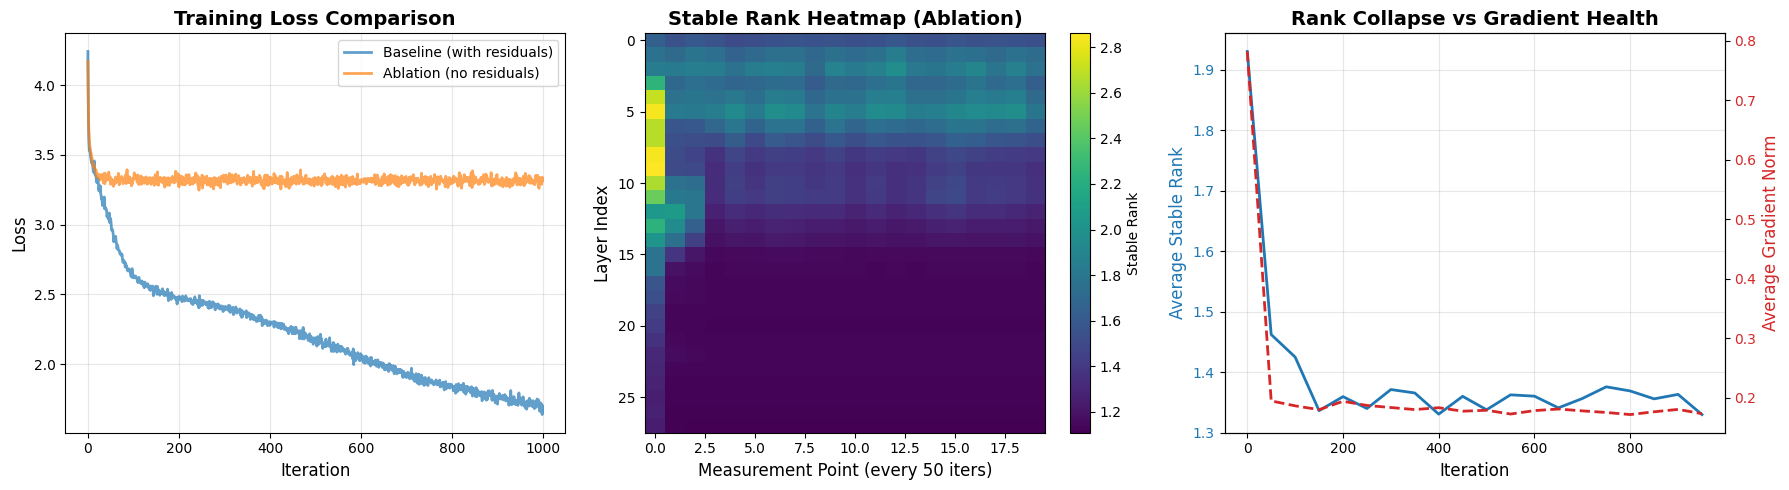


SUMMARY STATISTICS
Baseline Final Loss: 1.6996
Ablation Final Loss: 3.3145

Ablation Model - Final Stable Ranks by Layer:
  Layer  0: 1.54
  Layer  1: 1.73
  Layer  2: 1.76
  Layer  3: 1.64
  Layer  4: 1.71
  Layer  5: 1.79
  Layer  6: 1.68
  Layer  7: 1.53
  Layer  8: 1.40
  Layer  9: 1.35
  Layer 10: 1.36
  Layer 11: 1.37
  Layer 12: 1.28
  Layer 13: 1.23
  Layer 14: 1.19
  Layer 15: 1.15
  Layer 16: 1.14
  Layer 17: 1.13
  Layer 18: 1.14
  Layer 19: 1.13
  Layer 20: 1.13
  Layer 21: 1.13
  Layer 22: 1.13
  Layer 23: 1.13
  Layer 24: 1.13
  Layer 25: 1.12
  Layer 26: 1.12
  Layer 27: 1.11

Average Final Stable Rank: 1.33
Average Final Gradient Norm: 0.1729


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
import requests
from collections import defaultdict

# Download Tiny Shakespeare
def download_dataset():
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    response = requests.get(url)
    with open('tiny_shakespeare.txt', 'w', encoding='utf-8') as f:
        f.write(response.text)
    return response.text

# Character-level Dataset
class CharDataset(Dataset):
    def __init__(self, text, block_size):
        chars = sorted(list(set(text)))
        self.stoi = {ch: i for i, ch in enumerate(chars)}
        self.itos = {i: ch for i, ch in enumerate(chars)}
        self.vocab_size = len(chars)
        self.block_size = block_size
        self.data = [self.stoi[ch] for ch in text]
    
    def __len__(self):
        return len(self.data) - self.block_size
    
    def __getitem__(self, idx):
        x = torch.tensor(self.data[idx:idx+self.block_size], dtype=torch.long)
        y = torch.tensor(self.data[idx+1:idx+self.block_size+1], dtype=torch.long)
        return x, y

# Stable Rank Calculation
def stable_rank(matrix):
    """Compute stable rank: ||A||_F^2 / ||A||_2^2"""
    with torch.no_grad():
        frobenius_norm = torch.norm(matrix, p='fro')
        spectral_norm = torch.linalg.matrix_norm(matrix, ord=2)
        srank = (frobenius_norm ** 2) / (spectral_norm ** 2 + 1e-8)
    return srank.item()

# Multi-Head Self-Attention
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.n_embd = n_embd
        self.c_attn = nn.Linear(n_embd, 3 * n_embd)
        self.c_proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer("bias", torch.tril(torch.ones(block_size, block_size))
                                     .view(1, 1, block_size, block_size))
    
    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        
        att = (q @ k.transpose(-2, -1)) * (1.0 / np.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.resid_dropout(self.c_proj(y))
        return y

# MLP
class MLP(nn.Module):
    def __init__(self, n_embd, dropout=0.1):
        super().__init__()
        self.c_fc = nn.Linear(n_embd, 4 * n_embd)
        self.c_proj = nn.Linear(4 * n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        x = self.c_fc(x)
        x = F.gelu(x)
        x = self.c_proj(x)
        x = self.dropout(x)
        return x

# Transformer Block
class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, use_residual=True, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, dropout)
        self.use_residual = use_residual
    
    def forward(self, x):
        if self.use_residual:
            x = x + self.attn(self.ln_1(x))
            x = x + self.mlp(self.ln_2(x))
        else:
            x = self.attn(self.ln_1(x))
            x = self.mlp(self.ln_2(x))
        return x

# GPT Model
class GPT(nn.Module):
    def __init__(self, vocab_size, n_layer, n_head, n_embd, block_size, use_residual=True, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Parameter(torch.zeros(1, block_size, n_embd))
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, block_size, use_residual, dropout) 
                                     for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    
    def forward(self, idx):
        b, t = idx.size()
        assert t <= self.block_size
        tok_emb = self.tok_emb(idx)
        pos_emb = self.pos_emb[:, :t, :]
        x = self.drop(tok_emb + pos_emb)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.head(x)
        return logits

# Training Function with Metrics
def train_model(model, dataloader, optimizer, device, num_iters, track_metrics=True):
    model.train()
    losses = []
    stable_ranks = defaultdict(list)  # layer_idx -> list of ranks
    grad_norms = []
    
    iter_count = 0
    epoch = 0
    
    while iter_count < num_iters:
        epoch += 1
        for x, y in dataloader:
            if iter_count >= num_iters:
                break
            
            x, y = x.to(device), y.to(device)
            
            # Forward pass
            logits = model(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            
            # Track gradient norm
            if track_metrics:
                total_norm = 0.0
                for p in model.parameters():
                    if p.grad is not None:
                        total_norm += p.grad.data.norm(2).item() ** 2
                grad_norms.append(np.sqrt(total_norm))
            
            optimizer.step()
            
            losses.append(loss.item())
            
            # Track stable ranks every 50 iterations
            if track_metrics and iter_count % 50 == 0:
                with torch.no_grad():
                    # Forward pass to capture hidden states
                    tok_emb = model.tok_emb(x)
                    pos_emb = model.pos_emb[:, :x.size(1), :]
                    h = model.drop(tok_emb + pos_emb)
                    
                    for layer_idx, block in enumerate(model.blocks):
                        h = block(h)
                        # Compute stable rank on the hidden states
                        # Reshape to 2D: (batch*seq, embd)
                        h_2d = h.view(-1, h.size(-1))
                        srank = stable_rank(h_2d)
                        stable_ranks[layer_idx].append(srank)
            
            iter_count += 1
            
            if iter_count % 100 == 0:
                print(f"Iter {iter_count}/{num_iters}, Loss: {loss.item():.4f}")
    
    return losses, stable_ranks, grad_norms

# Main Execution
def main():
    # Configuration
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Using device: {device}")
    
    block_size = 128
    batch_size = 64
    n_layer = 28
    n_head = 6
    n_embd = 192
    num_iters = 1000
    lr = 3e-4
    
    # Download and prepare data
    print("Downloading Tiny Shakespeare...")
    text = download_dataset()
    dataset = CharDataset(text, block_size)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    vocab_size = dataset.vocab_size
    print(f"Vocabulary size: {vocab_size}")
    
    # Train Baseline Model (with residuals)
    print("\n" + "="*60)
    print("Training BASELINE model (with residual connections)")
    print("="*60)
    baseline_model = GPT(vocab_size, n_layer, n_head, n_embd, block_size, use_residual=True).to(device)
    baseline_optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=lr)
    baseline_losses, _, _ = train_model(baseline_model, dataloader, baseline_optimizer, 
                                        device, num_iters, track_metrics=False)
    
    # Train Ablation Model (without residuals)
    print("\n" + "="*60)
    print("Training ABLATION model (WITHOUT residual connections)")
    print("="*60)
    ablation_model = GPT(vocab_size, n_layer, n_head, n_embd, block_size, use_residual=False).to(device)
    ablation_optimizer = torch.optim.AdamW(ablation_model.parameters(), lr=lr)
    ablation_losses, ablation_ranks, ablation_grad_norms = train_model(
        ablation_model, dataloader, ablation_optimizer, device, num_iters, track_metrics=True)
    
    # Plotting
    print("\nGenerating plots...")
    fig = plt.figure(figsize=(18, 5))
    
    # Plot 1: Loss Curves
    ax1 = fig.add_subplot(131)
    ax1.plot(baseline_losses, label='Baseline (with residuals)', alpha=0.7, linewidth=2)
    ax1.plot(ablation_losses, label='Ablation (no residuals)', alpha=0.7, linewidth=2)
    ax1.set_xlabel('Iteration', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title('Training Loss Comparison', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(alpha=0.3)
    
    # Plot 2: Stable Rank Heatmap
    ax2 = fig.add_subplot(132)
    rank_matrix = np.zeros((n_layer, len(ablation_ranks[0])))
    for layer_idx in range(n_layer):
        rank_matrix[layer_idx, :] = ablation_ranks[layer_idx]
    
    im = ax2.imshow(rank_matrix, aspect='auto', cmap='viridis', interpolation='nearest')
    ax2.set_xlabel('Measurement Point (every 50 iters)', fontsize=12)
    ax2.set_ylabel('Layer Index', fontsize=12)
    ax2.set_title('Stable Rank Heatmap (Ablation)', fontsize=14, fontweight='bold')
    plt.colorbar(im, ax=ax2, label='Stable Rank')
    
    # Plot 3: Decoupling Plot (Rank vs Gradient Norm)
    ax3 = fig.add_subplot(133)
    avg_ranks = np.mean(rank_matrix, axis=0)
    measurement_points = np.arange(len(avg_ranks)) * 50
    
    color1 = 'tab:blue'
    ax3.set_xlabel('Iteration', fontsize=12)
    ax3.set_ylabel('Average Stable Rank', color=color1, fontsize=12)
    ax3.plot(measurement_points, avg_ranks, color=color1, linewidth=2, label='Avg Stable Rank')
    ax3.tick_params(axis='y', labelcolor=color1)
    ax3.grid(alpha=0.3)
    
    ax3_twin = ax3.twinx()
    color2 = 'tab:red'
    ax3_twin.set_ylabel('Average Gradient Norm', color=color2, fontsize=12)
    
    # Bin gradient norms to match rank measurements
    binned_grad_norms = []
    for i in range(len(avg_ranks)):
        start_idx = i * 50
        end_idx = min((i + 1) * 50, len(ablation_grad_norms))
        binned_grad_norms.append(np.mean(ablation_grad_norms[start_idx:end_idx]))
    
    ax3_twin.plot(measurement_points, binned_grad_norms, color=color2, 
                  linewidth=2, linestyle='--', label='Avg Gradient Norm')
    ax3_twin.tick_params(axis='y', labelcolor=color2)
    
    ax3.set_title('Rank Collapse vs Gradient Health', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('rank_collapse_analysis.png', dpi=300, bbox_inches='tight')
    print("Plots saved as 'rank_collapse_analysis.png'")
    plt.show()
    
    # Summary Statistics
    print("\n" + "="*60)
    print("SUMMARY STATISTICS")
    print("="*60)
    print(f"Baseline Final Loss: {baseline_losses[-1]:.4f}")
    print(f"Ablation Final Loss: {ablation_losses[-1]:.4f}")
    print(f"\nAblation Model - Final Stable Ranks by Layer:")
    for layer_idx in range(n_layer):
        final_rank = ablation_ranks[layer_idx][-1]
        print(f"  Layer {layer_idx:2d}: {final_rank:.2f}")
    print(f"\nAverage Final Stable Rank: {np.mean([ablation_ranks[i][-1] for i in range(n_layer)]):.2f}")
    print(f"Average Final Gradient Norm: {np.mean(ablation_grad_norms[-50:]):.4f}")

if __name__ == "__main__":
    main()